# AI/Automation Spend in Banking Sector Analysis

## Objective
Analyze AI and automation spending across banks, countries, regions, technologies, and use cases, and evaluate business impact through cost savings, ROI, automation, and productivity.

### Key analysis areas
- Data loading and validation
- Data cleaning and preprocessing
- Descriptive statistics using Pandas and NumPy
- AI spending and cost savings analysis
- ROI and automation analysis
- Country, region, bank, technology and use-case comparisons
- Year-wise trends
- Correlation analysis
- Business insights

**Libraries used:** Pandas, NumPy, Matplotlib, Seaborn

In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================
# LOAD BANKING AI / AUTOMATION DATASET
# ============================================

from pathlib import Path
import pandas as pd
import numpy as np

# Current project folder
PROJECT_DIR = Path.cwd()

print("Project folder:")
print(PROJECT_DIR)

# Find ALL CSV files inside the project
csv_files = list(PROJECT_DIR.rglob("*.csv"))

print("\nCSV files found:")

if csv_files:
    for i, file in enumerate(csv_files, start=1):
        print(f"{i}. {file}")
else:
    raise FileNotFoundError(
        "No CSV file found inside the project folder."
    )

# Select the first CSV file
FILE_PATH = csv_files[0]

print("\nUsing CSV file:")
print(FILE_PATH)

# Load dataset
df = pd.read_csv(FILE_PATH)

print("\n===================================")
print("Dataset loaded successfully!")
print("===================================")

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Project folder:
d:\AIAutomation Spend in Banking Sector Analysis

CSV files found:
1. d:\AIAutomation Spend in Banking Sector Analysis\data\AI_Automation_Banking_Spend_Raw_Data.csv

Using CSV file:
d:\AIAutomation Spend in Banking Sector Analysis\data\AI_Automation_Banking_Spend_Raw_Data.csv

Dataset loaded successfully!
Shape: (72, 13)

Columns:
['Year', 'Region', 'Country', 'Bank', 'AI_Use_Case', 'Technology', 'AI_Spend_USD_Million', 'Estimated_Cost_Savings_USD_Million', 'ROI_Multiple', 'Automation_Rate_Percent', 'FTE_Hours_Saved_Monthly', 'AI_Projects', 'Maturity']

First 5 records:


,Year,Region,Country,Bank,AI_Use_Case,Technology,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,ROI_Multiple,Automation_Rate_Percent,FTE_Hours_Saved_Monthly,AI_Projects,Maturity
0,2020,North America,USA,Citigroup,AML Monitoring,Machine Learning,1.50,0.37,1.41,24.40,1153,8,Scaling
1,2020,North America,Canada,TD Bank,Document Processing,RPA + AI,3.43,4.54,4.20,73.20,985,1,Pilot
2,2020,Europe,UK,Barclays,Code Generation,Generative AI,3.76,2.16,2.25,23.40,219,15,Scaling
3,2020,Europe,Germany,Commerzbank,IT Operations,AI Automation,1.50,1.71,2.88,74.00,676,9,Pilot
4,2020,Europe,France,Societe Generale,Code Generation,Generative AI,1.50,1.03,2.78,56.10,538,8,Pilot


## 1. Initial Data Understanding

In [4]:
# Basic information
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

Rows and columns: (72, 13)

Column names:
['Year', 'Region', 'Country', 'Bank', 'AI_Use_Case', 'Technology', 'AI_Spend_USD_Million', 'Estimated_Cost_Savings_USD_Million', 'ROI_Multiple', 'Automation_Rate_Percent', 'FTE_Hours_Saved_Monthly', 'AI_Projects', 'Maturity']

Data types:
Year                                    int64
Region                                 object
Country                                object
Bank                                   object
AI_Use_Case                            object
Technology                             object
AI_Spend_USD_Million                  float64
Estimated_Cost_Savings_USD_Million    float64
ROI_Multiple                          float64
Automation_Rate_Percent               float64
FTE_Hours_Saved_Monthly                 int64
AI_Projects                             int64
Maturity                               object
dtype: object

First 5 records:


,Year,Region,Country,Bank,AI_Use_Case,Technology,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,ROI_Multiple,Automation_Rate_Percent,FTE_Hours_Saved_Monthly,AI_Projects,Maturity
0,2020,North America,USA,Citigroup,AML Monitoring,Machine Learning,1.50,0.37,1.41,24.40,1153,8,Scaling
1,2020,North America,Canada,TD Bank,Document Processing,RPA + AI,3.43,4.54,4.20,73.20,985,1,Pilot
2,2020,Europe,UK,Barclays,Code Generation,Generative AI,3.76,2.16,2.25,23.40,219,15,Scaling
3,2020,Europe,Germany,Commerzbank,IT Operations,AI Automation,1.50,1.71,2.88,74.00,676,9,Pilot
4,2020,Europe,France,Societe Generale,Code Generation,Generative AI,1.50,1.03,2.78,56.10,538,8,Pilot



Last 5 records:


,Year,Region,Country,Bank,AI_Use_Case,Technology,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,ROI_Multiple,Automation_Rate_Percent,FTE_Hours_Saved_Monthly,AI_Projects,Maturity
67,2025,Asia-Pacific,Singapore,DBS Bank,IT Operations,AI Automation,5.62,8.97,3.71,46.40,167,17,Scaling
68,2025,Asia-Pacific,Japan,SMBC,AML Monitoring,Machine Learning,9.48,7.08,2.38,44.60,140,16,Pilot
69,2025,Asia-Pacific,Australia,Westpac,Marketing Personalization,Generative AI,8.73,11.19,3.71,25.80,696,5,Pilot
70,2025,Middle East,UAE,First Abu Dhabi Bank,KYC Automation,RPA + AI,2.69,3.02,3.01,36.90,1126,15,Scaling
71,2025,Middle East,Saudi Arabia,Saudi National Bank,Marketing Personalization,Generative AI,4.93,6.38,4.52,67.40,1079,4,Production


In [5]:
# Missing values and duplicate records
missing = df.isnull().sum().sort_values(ascending=False)
duplicates = df.duplicated().sum()

print("Missing values:")
display(missing.to_frame("Missing_Count"))

print("Total duplicate rows:", duplicates)

Missing values:


,Missing_Count
Year,0
Region,0
Country,0
Bank,0
AI_Use_Case,0
Technology,0
AI_Spend_USD_Million,0
Estimated_Cost_Savings_USD_Million,0
ROI_Multiple,0
Automation_Rate_Percent,0


Total duplicate rows: 0


In [6]:
# Descriptive statistics
print("Numerical summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Year,72.00,"2,022.50",1.72,"2,020.00","2,021.00","2,022.50","2,024.00","2,025.00"
AI_Spend_USD_Million,72.00,5.49,3.80,1.50,2.12,4.67,7.65,15.40
Estimated_Cost_Savings_USD_Million,72.00,5.60,5.32,0.37,1.81,3.67,6.68,23.62
ROI_Multiple,72.00,3.03,1.00,1.29,2.26,2.90,3.71,4.78
Automation_Rate_Percent,72.00,48.27,17.29,15.70,34.68,51.80,62.10,74.00
FTE_Hours_Saved_Monthly,72.00,682.19,343.48,66.00,424.00,683.50,986.25,"1,178.00"
AI_Projects,72.00,9.38,5.03,1.00,5.00,9.50,14.00,17.00



Categorical summary:


,count,unique,top,freq
Region,72,4,Europe,24
Country,72,12,USA,6
Bank,72,27,Societe Generale,4
AI_Use_Case,72,10,Document Processing,9
Technology,72,4,Generative AI,22
Maturity,72,3,Scaling,30


## 2. Data Cleaning and Preprocessing

The following steps:
1. Remove duplicate records.
2. Clean column names.
3. Remove unnecessary spaces from text fields.
4. Convert numeric columns to numeric data types.
5. Validate missing values and invalid numeric values.

In [7]:
# Clean column names
df.columns = (
    df.columns
      .str.strip()
      .str.replace(" ", "_")
      .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
)

# Remove duplicate rows
before = len(df)
df = df.drop_duplicates().copy()
after = len(df)

# Clean text columns
text_columns = df.select_dtypes(include="object").columns
for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

# Convert numeric columns
numeric_columns = [
    "Year",
    "AI_Spend_USD_Million",
    "Estimated_Cost_Savings_USD_Million",
    "ROI_Multiple",
    "Automation_Rate_Percent",
    "FTE_Hours_Saved_Monthly",
    "AI_Projects"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Duplicate rows removed: {before - after}")
print("Cleaned shape:", df.shape)
display(df.head())

# Handle missing values after numeric conversion
for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

for col in text_columns:
    if df[col].isnull().any():
        mode_value = df[col].mode(dropna=True)
        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])


Duplicate rows removed: 0
Cleaned shape: (72, 13)


,Year,Region,Country,Bank,AI_Use_Case,Technology,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,ROI_Multiple,Automation_Rate_Percent,FTE_Hours_Saved_Monthly,AI_Projects,Maturity
0,2020,North America,USA,Citigroup,AML Monitoring,Machine Learning,1.50,0.37,1.41,24.40,1153,8,Scaling
1,2020,North America,Canada,TD Bank,Document Processing,RPA + AI,3.43,4.54,4.20,73.20,985,1,Pilot
2,2020,Europe,UK,Barclays,Code Generation,Generative AI,3.76,2.16,2.25,23.40,219,15,Scaling
3,2020,Europe,Germany,Commerzbank,IT Operations,AI Automation,1.50,1.71,2.88,74.00,676,9,Pilot
4,2020,Europe,France,Societe Generale,Code Generation,Generative AI,1.50,1.03,2.78,56.10,538,8,Pilot


In [8]:
# Post-cleaning validation
print("Missing values after cleaning:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("Duplicate rows after cleaning:", df.duplicated().sum())

print("\nNumeric columns:")
display(df[numeric_columns].describe().T)

Missing values after cleaning:


,Missing_Count
Year,0
Region,0
Country,0
Bank,0
AI_Use_Case,0
Technology,0
AI_Spend_USD_Million,0
Estimated_Cost_Savings_USD_Million,0
ROI_Multiple,0
Automation_Rate_Percent,0


Duplicate rows after cleaning: 0

Numeric columns:


,count,mean,std,min,25%,50%,75%,max
Year,72.00,"2,022.50",1.72,"2,020.00","2,021.00","2,022.50","2,024.00","2,025.00"
AI_Spend_USD_Million,72.00,5.49,3.80,1.50,2.12,4.67,7.65,15.40
Estimated_Cost_Savings_USD_Million,72.00,5.60,5.32,0.37,1.81,3.67,6.68,23.62
ROI_Multiple,72.00,3.03,1.00,1.29,2.26,2.90,3.71,4.78
Automation_Rate_Percent,72.00,48.27,17.29,15.70,34.68,51.80,62.10,74.00
FTE_Hours_Saved_Monthly,72.00,682.19,343.48,66.00,424.00,683.50,986.25,"1,178.00"
AI_Projects,72.00,9.38,5.03,1.00,5.00,9.50,14.00,17.00


## 3. Feature Engineering

In [9]:
# Derived business metrics
df["Net_Benefit_USD_Million"] = (
    df["Estimated_Cost_Savings_USD_Million"] - df["AI_Spend_USD_Million"]
)

df["Savings_to_Spend_Ratio"] = np.where(
    df["AI_Spend_USD_Million"] != 0,
    df["Estimated_Cost_Savings_USD_Million"] / df["AI_Spend_USD_Million"],
    np.nan
)

df["Total_Impact_Score"] = (
    df["ROI_Multiple"] *
    (1 + df["Automation_Rate_Percent"] / 100) *
    (1 + df["AI_Projects"] / 10)
)

display(df[[
    "AI_Spend_USD_Million",
    "Estimated_Cost_Savings_USD_Million",
    "Net_Benefit_USD_Million",
    "Savings_to_Spend_Ratio",
    "ROI_Multiple",
    "Automation_Rate_Percent",
    "AI_Projects",
    "Total_Impact_Score"
]].head())

,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,Net_Benefit_USD_Million,Savings_to_Spend_Ratio,ROI_Multiple,Automation_Rate_Percent,AI_Projects,Total_Impact_Score
0,1.50,0.37,-1.13,0.25,1.41,24.40,8,3.16
1,3.43,4.54,1.11,1.32,4.20,73.20,1,8.00
2,3.76,2.16,-1.60,0.57,2.25,23.40,15,6.94
3,1.50,1.71,0.21,1.14,2.88,74.00,9,9.52
4,1.50,1.03,-0.47,0.69,2.78,56.10,8,7.81


## 4. Exploratory Data Analysis (EDA)

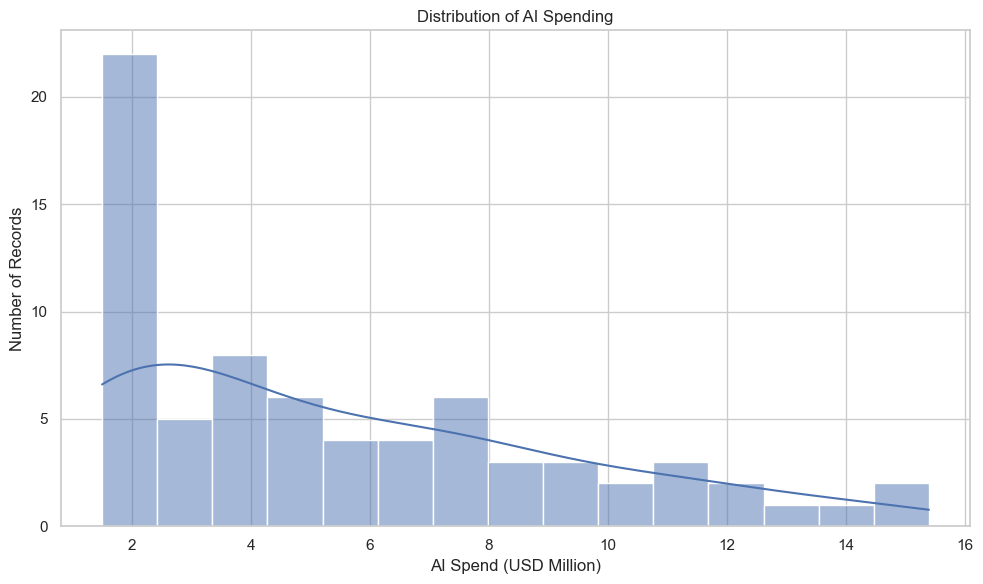

In [10]:
# Distribution of AI spending
plt.figure(figsize=(10, 6))
sns.histplot(df["AI_Spend_USD_Million"], bins=15, kde=True)
plt.title("Distribution of AI Spending")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

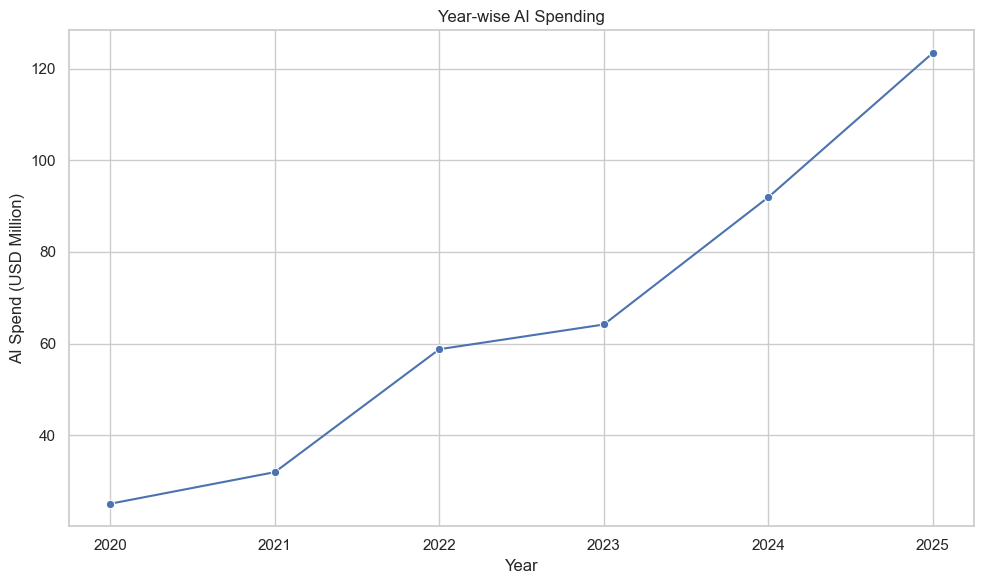

,Year,AI_Spend_USD_Million
0,2020,25.00
1,2021,31.90
2,2022,58.76
3,2023,64.16
4,2024,91.98
5,2025,123.51


In [11]:
# AI spending by year
year_spend = df.groupby("Year", as_index=False)["AI_Spend_USD_Million"].sum()

plt.figure(figsize=(10, 6))
sns.lineplot(data=year_spend, x="Year", y="AI_Spend_USD_Million", marker="o")
plt.title("Year-wise AI Spending")
plt.xlabel("Year")
plt.ylabel("AI Spend (USD Million)")
plt.tight_layout()
plt.show()

display(year_spend)

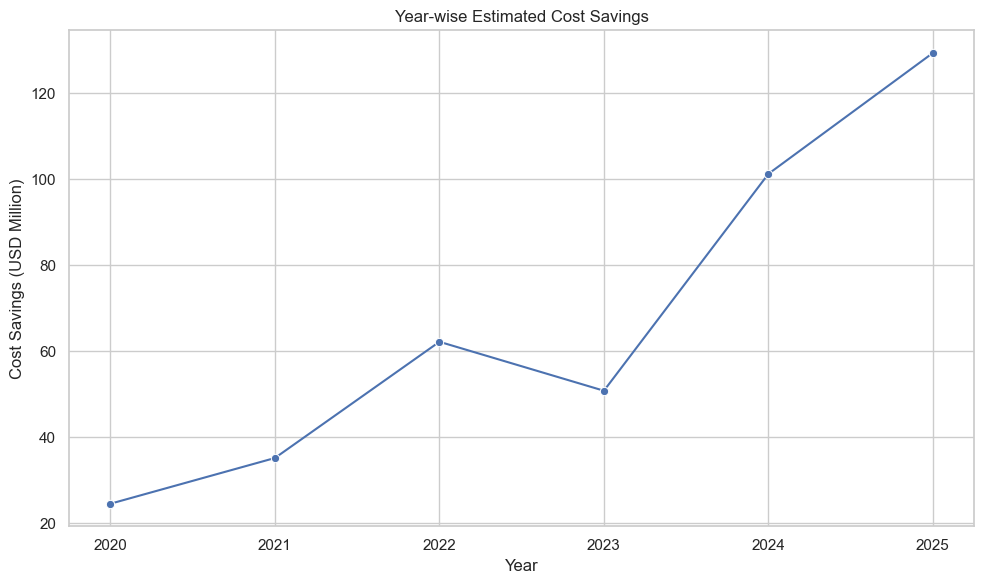

In [12]:
# Cost savings by year
year_savings = df.groupby("Year", as_index=False)["Estimated_Cost_Savings_USD_Million"].sum()

plt.figure(figsize=(10, 6))
sns.lineplot(data=year_savings, x="Year", y="Estimated_Cost_Savings_USD_Million", marker="o")
plt.title("Year-wise Estimated Cost Savings")
plt.xlabel("Year")
plt.ylabel("Cost Savings (USD Million)")
plt.tight_layout()
plt.show()

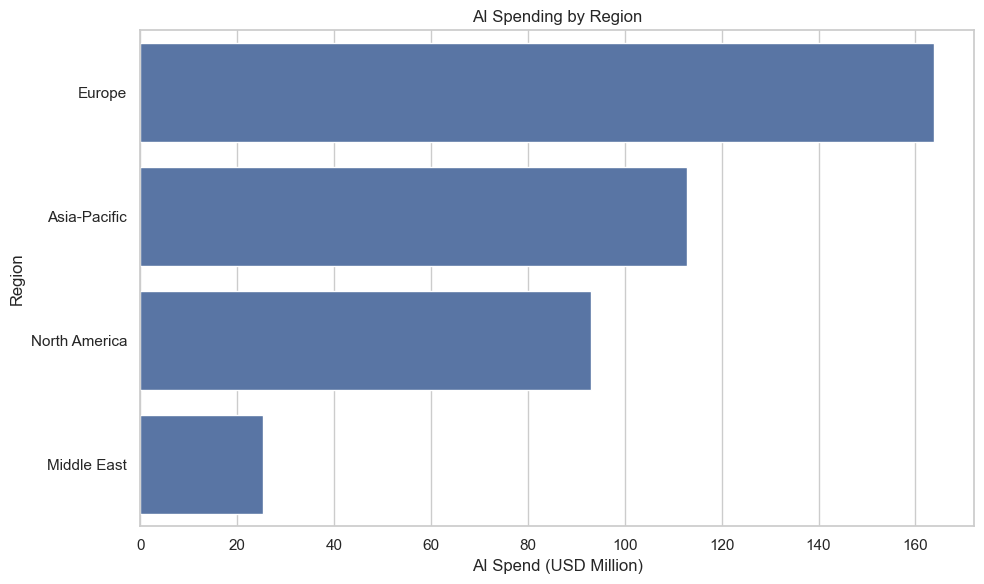

,Region,AI_Spend_USD_Million
1,Europe,163.90
0,Asia-Pacific,112.90
3,North America,93.11
2,Middle East,25.40


In [13]:
# AI spending by region
region_spend = (
    df.groupby("Region", as_index=False)["AI_Spend_USD_Million"]
      .sum()
      .sort_values("AI_Spend_USD_Million", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=region_spend, x="AI_Spend_USD_Million", y="Region")
plt.title("AI Spending by Region")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

display(region_spend)

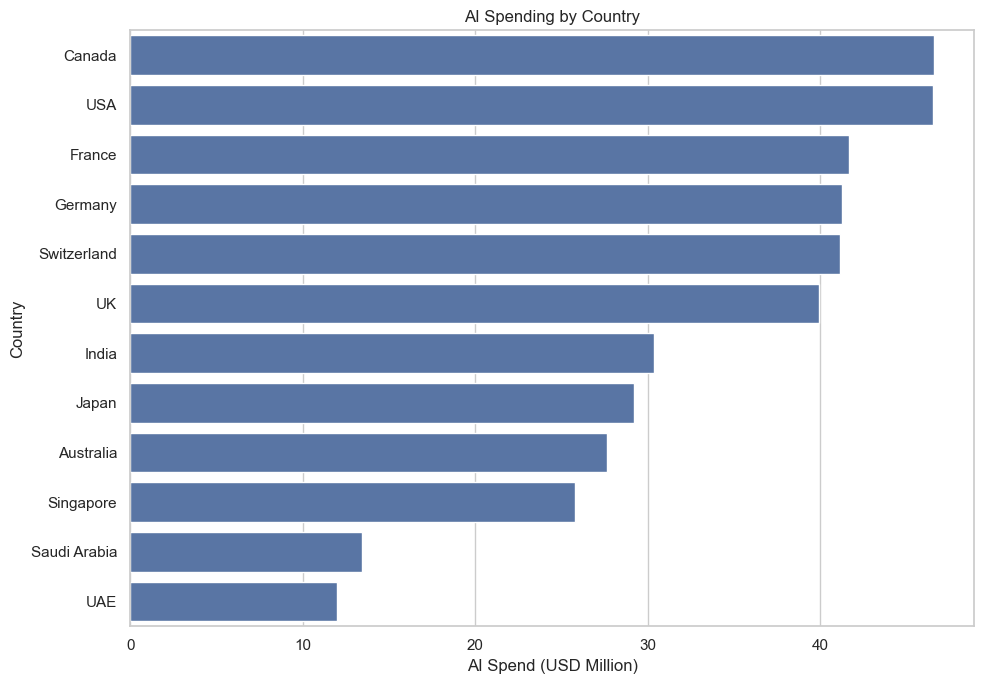

,Country,AI_Spend_USD_Million
1,Canada,46.57
11,USA,46.54
2,France,41.64
3,Germany,41.22
8,Switzerland,41.11
10,UK,39.93
4,India,30.35
5,Japan,29.18
0,Australia,27.60
7,Singapore,25.77


In [14]:
# AI spending by country
country_spend = (
    df.groupby("Country", as_index=False)["AI_Spend_USD_Million"]
      .sum()
      .sort_values("AI_Spend_USD_Million", ascending=False)
)

plt.figure(figsize=(10, 7))
sns.barplot(data=country_spend, x="AI_Spend_USD_Million", y="Country")
plt.title("AI Spending by Country")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_spend)

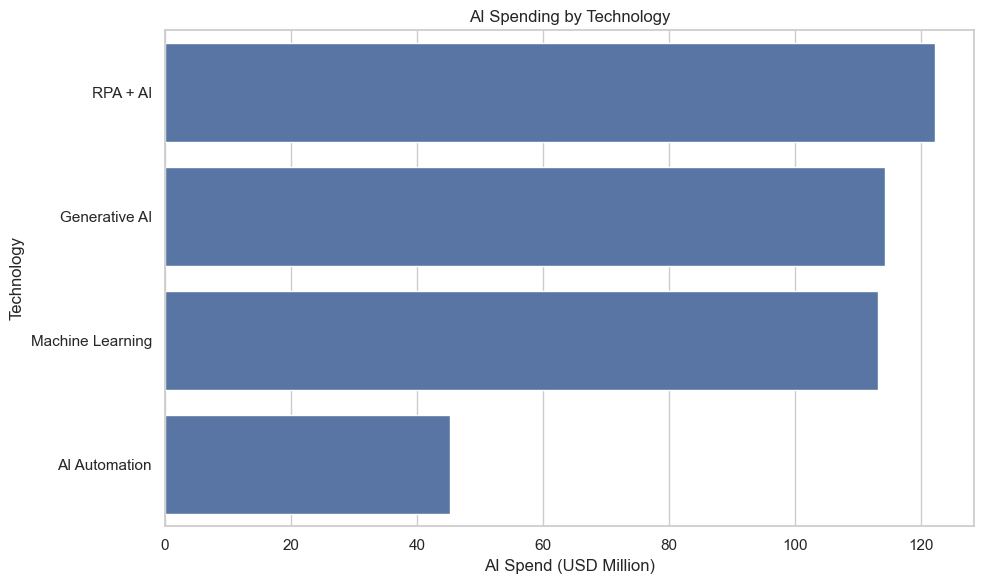

In [15]:
# AI spending by technology
technology_spend = (
    df.groupby("Technology", as_index=False)["AI_Spend_USD_Million"]
      .sum()
      .sort_values("AI_Spend_USD_Million", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=technology_spend, x="AI_Spend_USD_Million", y="Technology")
plt.title("AI Spending by Technology")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Technology")
plt.tight_layout()
plt.show()

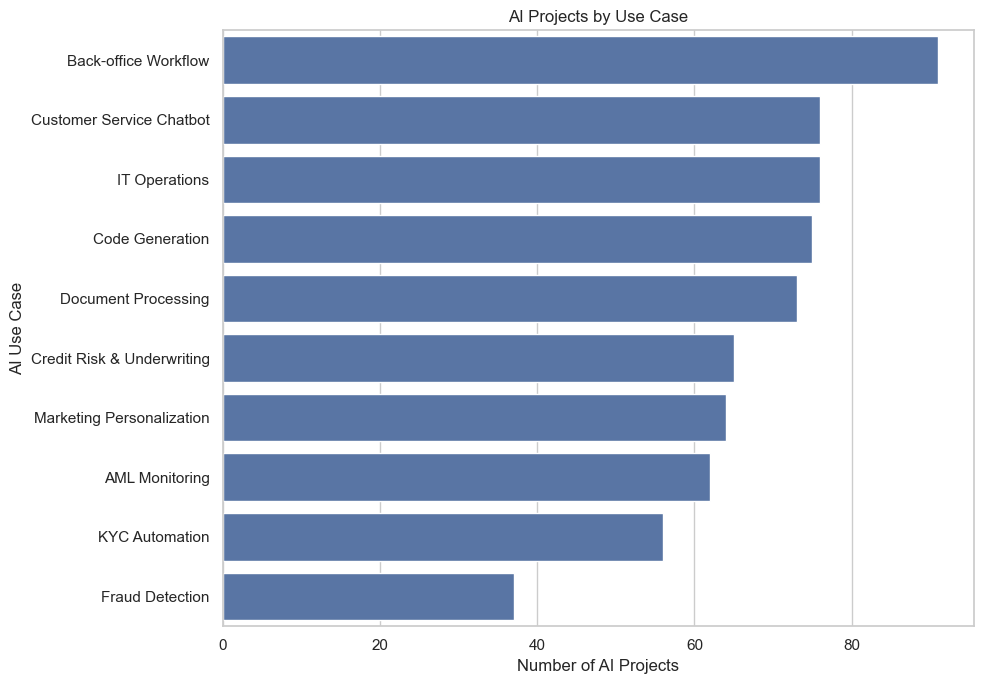

In [16]:
# AI projects by use case
use_case_projects = (
    df.groupby("AI_Use_Case", as_index=False)["AI_Projects"]
      .sum()
      .sort_values("AI_Projects", ascending=False)
)

plt.figure(figsize=(10, 7))
sns.barplot(data=use_case_projects, x="AI_Projects", y="AI_Use_Case")
plt.title("AI Projects by Use Case")
plt.xlabel("Number of AI Projects")
plt.ylabel("AI Use Case")
plt.tight_layout()
plt.show()

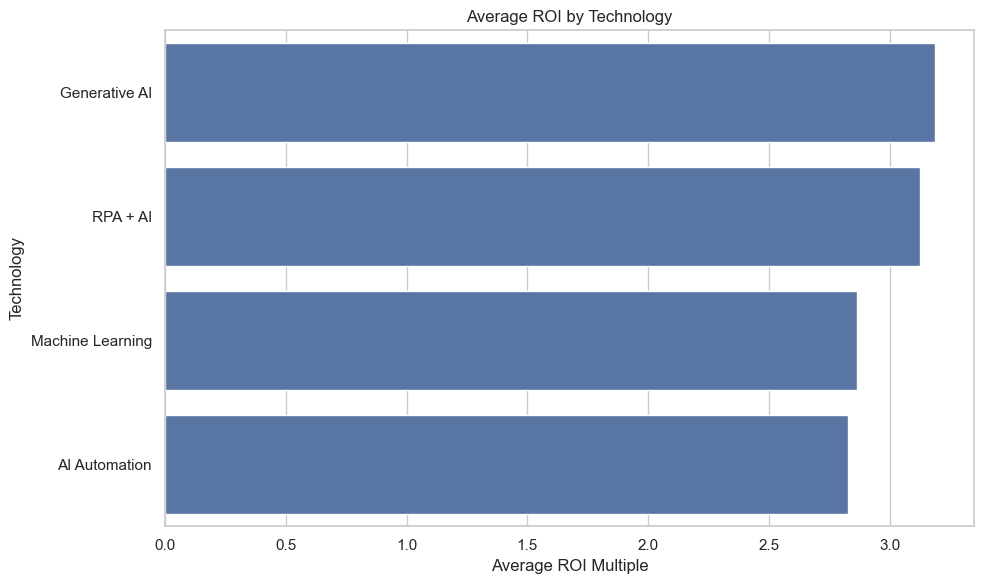

In [17]:
# Average ROI by technology
technology_roi = (
    df.groupby("Technology", as_index=False)["ROI_Multiple"]
      .mean()
      .sort_values("ROI_Multiple", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=technology_roi, x="ROI_Multiple", y="Technology")
plt.title("Average ROI by Technology")
plt.xlabel("Average ROI Multiple")
plt.ylabel("Technology")
plt.tight_layout()
plt.show()

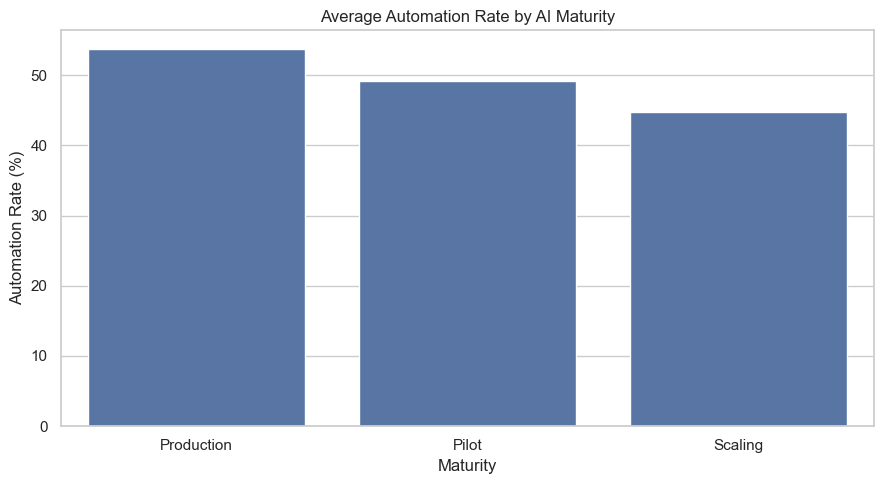

In [18]:
# Average automation rate by maturity
maturity_automation = (
    df.groupby("Maturity", as_index=False)["Automation_Rate_Percent"]
      .mean()
      .sort_values("Automation_Rate_Percent", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(data=maturity_automation, x="Maturity", y="Automation_Rate_Percent")
plt.title("Average Automation Rate by AI Maturity")
plt.xlabel("Maturity")
plt.ylabel("Automation Rate (%)")
plt.tight_layout()
plt.show()

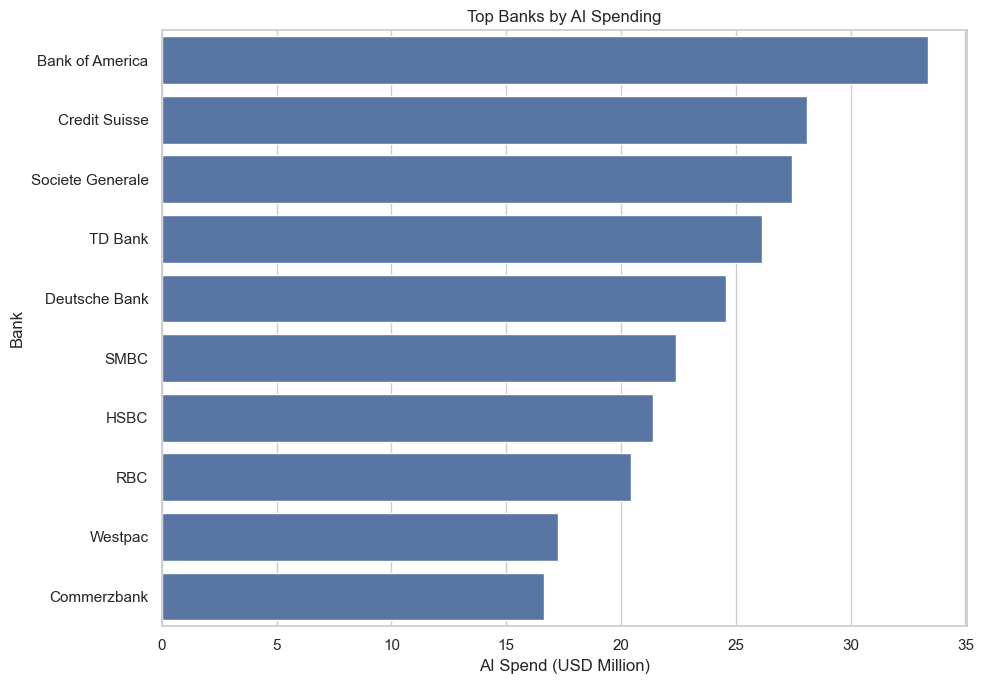

,Bank,AI_Spend_USD_Million
2,Bank of America,33.39
7,Credit Suisse,28.11
22,Societe Generale,27.43
24,TD Bank,26.14
9,Deutsche Bank,24.58
20,SMBC,22.38
13,HSBC,21.41
19,RBC,20.43
26,Westpac,17.26
5,Commerzbank,16.64


In [19]:
# Top banks by AI spending
bank_spend = (
    df.groupby("Bank", as_index=False)["AI_Spend_USD_Million"]
      .sum()
      .sort_values("AI_Spend_USD_Million", ascending=False)
)

top_banks = bank_spend.head(10)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_banks, x="AI_Spend_USD_Million", y="Bank")
plt.title("Top Banks by AI Spending")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Bank")
plt.tight_layout()
plt.show()

display(top_banks)

## 5. Relationship and Correlation Analysis

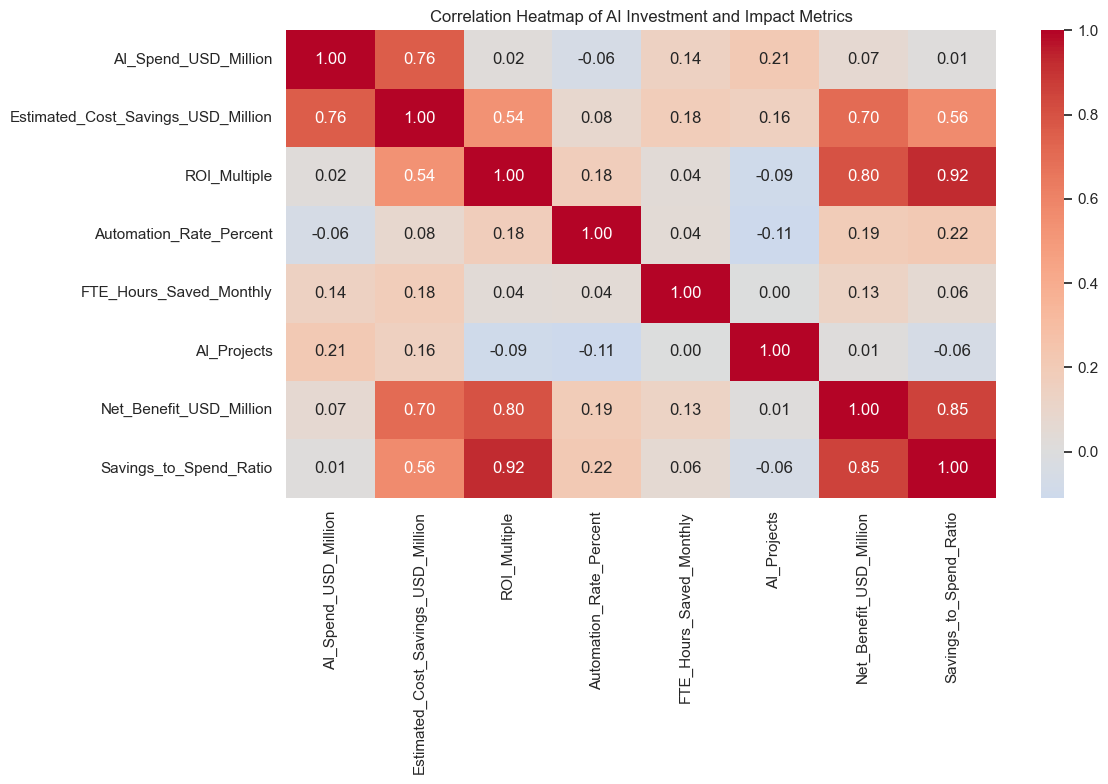

In [20]:
# Correlation matrix
corr_columns = [
    "AI_Spend_USD_Million",
    "Estimated_Cost_Savings_USD_Million",
    "ROI_Multiple",
    "Automation_Rate_Percent",
    "FTE_Hours_Saved_Monthly",
    "AI_Projects",
    "Net_Benefit_USD_Million",
    "Savings_to_Spend_Ratio"
]

correlation = df[corr_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of AI Investment and Impact Metrics")
plt.tight_layout()
plt.show()

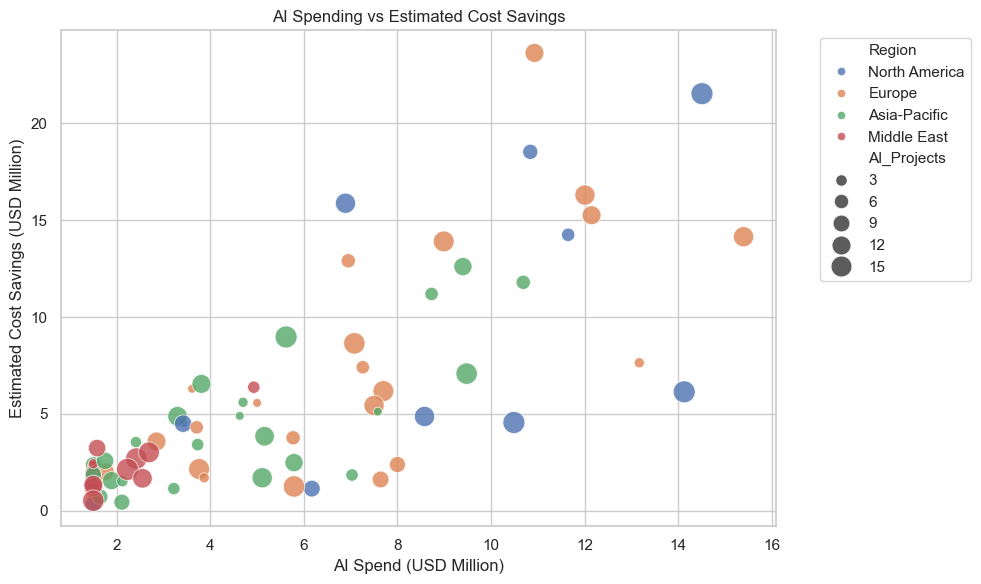

In [21]:
# AI spending vs estimated cost savings
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="AI_Spend_USD_Million",
    y="Estimated_Cost_Savings_USD_Million",
    hue="Region",
    size="AI_Projects",
    sizes=(40, 250),
    alpha=0.8
)
plt.title("AI Spending vs Estimated Cost Savings")
plt.xlabel("AI Spend (USD Million)")
plt.ylabel("Estimated Cost Savings (USD Million)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

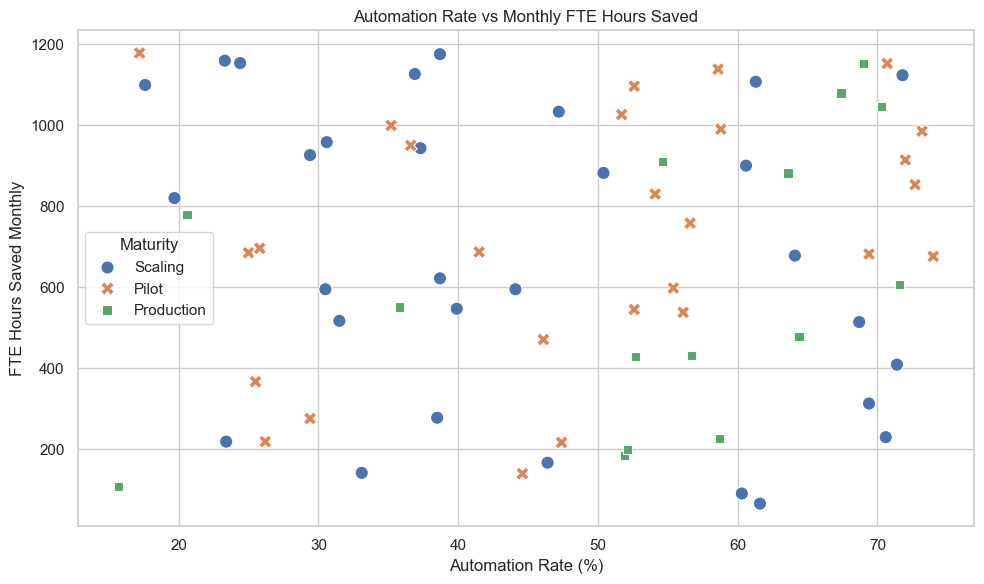

In [22]:
# Automation rate vs FTE hours saved
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Automation_Rate_Percent",
    y="FTE_Hours_Saved_Monthly",
    hue="Maturity",
    style="Maturity",
    s=90
)
plt.title("Automation Rate vs Monthly FTE Hours Saved")
plt.xlabel("Automation Rate (%)")
plt.ylabel("FTE Hours Saved Monthly")
plt.tight_layout()
plt.show()

## 6. Key Business Metrics

In [23]:
# Overall KPI summary
total_spend = df["AI_Spend_USD_Million"].sum()
total_savings = df["Estimated_Cost_Savings_USD_Million"].sum()
total_projects = df["AI_Projects"].sum()
avg_roi = df["ROI_Multiple"].mean()
avg_automation = df["Automation_Rate_Percent"].mean()
total_fte_hours = df["FTE_Hours_Saved_Monthly"].sum()
net_benefit = df["Net_Benefit_USD_Million"].sum()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total AI Spend (USD Million)",
        "Total Estimated Cost Savings (USD Million)",
        "Net Benefit (USD Million)",
        "Total AI Projects",
        "Average ROI Multiple",
        "Average Automation Rate (%)",
        "Total Monthly FTE Hours Saved"
    ],
    "Value": [
        total_spend,
        total_savings,
        net_benefit,
        total_projects,
        avg_roi,
        avg_automation,
        total_fte_hours
    ]
})

display(kpi_summary)

,Metric,Value
0,Total AI Spend (USD Million),395.31
1,Total Estimated Cost Savings (USD Million),403.37
2,Net Benefit (USD Million),8.06
3,Total AI Projects,675.00
4,Average ROI Multiple,3.03
5,Average Automation Rate (%),48.27
6,Total Monthly FTE Hours Saved,"49,118.00"


## 7. Top and Bottom Performance

In [24]:
# Highest ROI records
top_roi = df.nlargest(10, "ROI_Multiple")[[
    "Year", "Country", "Bank", "AI_Use_Case", "Technology",
    "AI_Spend_USD_Million", "Estimated_Cost_Savings_USD_Million",
    "ROI_Multiple", "Maturity"
]]

print("Top 10 ROI records:")
display(top_roi)

# Highest automation records
top_automation = df.nlargest(10, "Automation_Rate_Percent")[[
    "Year", "Country", "Bank", "AI_Use_Case", "Automation_Rate_Percent",
    "FTE_Hours_Saved_Monthly", "Maturity"
]]

print("Top 10 automation records:")
display(top_automation)

Top 10 ROI records:


,Year,Country,Bank,AI_Use_Case,Technology,AI_Spend_USD_Million,Estimated_Cost_Savings_USD_Million,ROI_Multiple,Maturity
28,2022,France,BNP Paribas,Credit Risk & Underwriting,Machine Learning,6.95,12.90,4.78,Scaling
31,2022,Singapore,OCBC Bank,Customer Service Chatbot,Generative AI,1.75,2.58,4.76,Production
52,2024,France,Societe Generale,Customer Service Chatbot,Generative AI,10.93,23.62,4.75,Scaling
60,2025,USA,Bank of America,Document Processing,RPA + AI,14.51,21.52,4.75,Production
55,2024,Singapore,OCBC Bank,Back-office Workflow,RPA + AI,9.40,12.60,4.69,Production
59,2024,Saudi Arabia,Saudi National Bank,Credit Risk & Underwriting,Machine Learning,1.58,3.24,4.62,Production
24,2022,USA,Bank of America,Marketing Personalization,Generative AI,6.89,15.87,4.58,Scaling
71,2025,Saudi Arabia,Saudi National Bank,Marketing Personalization,Generative AI,4.93,6.38,4.52,Production
14,2021,UK,HSBC,Document Processing,RPA + AI,3.61,6.30,4.41,Pilot
50,2024,UK,Barclays,Back-office Workflow,RPA + AI,8.99,13.90,4.40,Pilot


Top 10 automation records:


,Year,Country,Bank,AI_Use_Case,Automation_Rate_Percent,FTE_Hours_Saved_Monthly,Maturity
3,2020,Germany,Commerzbank,IT Operations,74.00,676,Pilot
1,2020,Canada,TD Bank,Document Processing,73.20,985,Pilot
54,2024,India,HDFC Bank,IT Operations,72.70,853,Pilot
48,2024,USA,JPMorgan Chase,Credit Risk & Underwriting,72.00,914,Pilot
52,2024,France,Societe Generale,Customer Service Chatbot,71.80,1123,Scaling
13,2021,Canada,RBC,AML Monitoring,71.60,607,Production
42,2023,India,State Bank of India,Customer Service Chatbot,71.40,409,Scaling
29,2022,Switzerland,UBS,Document Processing,70.70,1152,Pilot
9,2020,Australia,Commonwealth Bank,Document Processing,70.60,230,Scaling
6,2020,India,HDFC Bank,Customer Service Chatbot,70.30,1046,Production


## 8. Automated Business Insights

In [25]:
# Generate concise data-driven insights

highest_spend_country = country_spend.iloc[0]
highest_spend_region = region_spend.iloc[0]
highest_roi_tech = technology_roi.iloc[0]
highest_automation_maturity = maturity_automation.iloc[0]
highest_use_case = use_case_projects.iloc[0]

print("BUSINESS INSIGHTS")
print("-" * 60)

print(
    f"1. Highest total AI spending country: "
    f"{highest_spend_country['Country']} "
    f"({highest_spend_country['AI_Spend_USD_Million']:.2f} USD million)."
)

print(
    f"2. Highest total AI spending region: "
    f"{highest_spend_region['Region']} "
    f"({highest_spend_region['AI_Spend_USD_Million']:.2f} USD million)."
)

print(
    f"3. Technology with highest average ROI: "
    f"{highest_roi_tech['Technology']} "
    f"({highest_roi_tech['ROI_Multiple']:.2f}x average ROI)."
)

print(
    f"4. Maturity category with highest average automation rate: "
    f"{highest_automation_maturity['Maturity']} "
    f"({highest_automation_maturity['Automation_Rate_Percent']:.2f}%)."
)

print(
    f"5. Use case with the highest number of AI projects: "
    f"{highest_use_case['AI_Use_Case']} "
    f"({highest_use_case['AI_Projects']:.0f} projects)."
)

print(
    f"6. Overall AI spending: {total_spend:.2f} USD million, "
    f"while estimated cost savings are {total_savings:.2f} USD million."
)

print(
    f"7. Average ROI across all records is {avg_roi:.2f}x "
    f"and average automation rate is {avg_automation:.2f}%."
)

BUSINESS INSIGHTS
------------------------------------------------------------
1. Highest total AI spending country: Canada (46.57 USD million).
2. Highest total AI spending region: Europe (163.90 USD million).
3. Technology with highest average ROI: Generative AI (3.19x average ROI).
4. Maturity category with highest average automation rate: Production (53.67%).
5. Use case with the highest number of AI projects: Back-office Workflow (91 projects).
6. Overall AI spending: 395.31 USD million, while estimated cost savings are 403.37 USD million.
7. Average ROI across all records is 3.03x and average automation rate is 48.27%.


## 9. Save Cleaned Dataset

The cleaned and feature-engineered dataset can be used later in SQL and Power BI.

In [26]:
# Save processed dataset
OUTPUT_FILE = "AI_Banking_Investment_Analysis_Cleaned.csv"
df.to_csv(OUTPUT_FILE, index=False)

print(f"Cleaned dataset saved as: {OUTPUT_FILE}")
print("Final dataset shape:", df.shape)

Cleaned dataset saved as: AI_Banking_Investment_Analysis_Cleaned.csv
Final dataset shape: (72, 16)


## 10. Final Conclusion

This analysis examines AI investment and business impact across banking organizations.

The notebook covers:
- Pandas for data loading, cleaning, grouping, aggregation and analysis.
- NumPy for numerical calculations and derived metrics.
- Matplotlib and Seaborn for all charts, plots and the correlation heatmap.
- Investment, cost savings, ROI, automation, FTE hours saved and AI project analysis.
- Country, region, bank, technology, maturity and use-case comparisons.

### Resume-ready project description
**AI/Automation Spend in Banking Sector Analysis:** Performed end-to-end data cleaning and exploratory data analysis on banking AI investment data using Python, Pandas and NumPy. Analyzed AI spending, cost savings, ROI, automation and project adoption across countries, regions, technologies and use cases. Built business-focused visualizations and correlation heatmaps using Matplotlib and Seaborn and generated actionable insights for investment and operational impact.

## Tools Used

- **Pandas:** data loading, cleaning, grouping, transformation and analysis
- **NumPy:** numerical calculations and derived metrics
- **Matplotlib:** charts and plots
- **Seaborn:** statistical visualizations and correlation heatmaps

All charts, plots and heatmaps in this project are built using **Matplotlib and Seaborn**.

In [27]:
# Save cleaned dataset for Power BI / further analysis
CLEANED_PATH = PROJECT_DIR / "data" / "AI_Automation_Spend_Cleaned_Data.csv"
CLEANED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEANED_PATH, index=False)

print("Cleaned dataset saved successfully:")
print(CLEANED_PATH)


Cleaned dataset saved successfully:
d:\AIAutomation Spend in Banking Sector Analysis\data\AI_Automation_Spend_Cleaned_Data.csv
